# CS 6220 — Homework 4
## Frequent Itemsets, Association Rules, and Hierarchical Clustering

**Course:** CS 6220 — Data Mining Techniques  
**Deliverables:** this notebook (all cells executed), `HW4_Report.pdf`, and the source in this repository.

---

### Contents

| Section | Topic |
|---|---|
| **0** | [Setup and reproducibility](#0-Setup-and-reproducibility) |
| **1** | [Part 1 — Frequent itemsets with Apriori](#Part-1---Frequent-Itemsets) |
| **2** | [Part 2 — Association rules with `Apriori_rules`](#Part-2---Association-Rules) |
| **3** | [Part 3 — Hierarchical agglomerative clustering](#Part-3---Hierarchical-Agglomerative-Clustering) |
| **4** | [Answers to the report questions](#Summary-of-findings) |

**Repository layout**

```
CS6220HW4/
├── CS6220_HW4.ipynb      this notebook: implementations + experiments
├── HW4_Report.pdf        the written report (answers Q1-Q12)
├── clustering.txt        2-D dataset for Part 3 (370 points)
├── requirements.txt      Python dependencies
├── figures/              figures produced by this notebook
├── results/              hw4_results.json (all numbers used in the report)
└── tools/                report build script
```

The notebook is the single source of truth: it defines every algorithm, runs every
experiment, and writes the numbers and figures that the PDF report is assembled from.

## 0. Setup and reproducibility

**Dependencies** are pinned in `requirements.txt`. To reproduce everything:

```bash
python -m pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace CS6220_HW4.ipynb
```

The cell below imports the libraries, fixes the plotting style, and creates the
output folders. All randomness is seeded, so plots and numbers are reproducible.

In [1]:
# ---------------------------------------------------------------------------
# Imports, global configuration and output folders.
# ---------------------------------------------------------------------------
import json
import math
import os
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

# NOTE: the backend is left to the kernel (inline), so figures render in the
# notebook *and* are written to figures/ for the PDF report.

FIG_DIR = os.path.join(os.getcwd(), "figures")
RESULT_DIR = os.path.join(os.getcwd(), "results")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 9,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

SEED = 6220
RNG = np.random.default_rng(SEED)

print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__}")
print("working directory:", os.getcwd())

numpy 2.5.4 | matplotlib 3.11.2
working directory: C:\Users\hammerhao\Documents\GitHub\CS6220HW4


<a id="Part-1---Frequent-Itemsets"></a>
# Part 1 — Frequent Itemsets

## 1.1 The transaction database

The assignment defines 20 transactions over 12 distinct items. `transactions` below
holds the raw list exactly as given; `TRANS_SETS` is the same data converted once to
`frozenset`s, because subset tests (`itemset <= transaction`) are the inner loop of
every support count and set lookup is much cheaper than list scanning.

In [2]:
transactions = [
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter", "Eggs"],
    ["Milk", "Cereal"],
    ["Bread", "Eggs"],
    ["Milk", "Cereal", "Yogurt"],
    ["Diapers", "Beer"],
    ["Diapers", "Beer", "Chips"],
    ["Apples", "Bananas"],
    ["Apples", "Bananas", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Cereal", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Apples", "Milk"],
    ["Diapers", "Beer", "Bread", "Eggs"],
    ["Yogurt", "Cereal"],
    ["Bread", "Butter", "Bananas", "Milk"],
    ["Milk", "Eggs"],
    ["Apples", "Bananas", "Yogurt"],
    ["Bread", "Butter", "Cereal", "Milk"],
    ["Chips", "Salsa"],
]

# Frozen-set view used by all support computations (one conversion, not per test).
TRANS_SETS = [frozenset(t) for t in transactions]
N_TRANS = len(TRANS_SETS)

item_counts = Counter(item for t in TRANS_SETS for item in t)
print(f"{N_TRANS} transactions, {len(item_counts)} distinct items")
print(f"absolute count equivalent to min_sup = 0.25 : {0.25 * N_TRANS:.0f} transactions\n")

print(f"{'item':<10}{'count':>6}{'support':>10}")
print("-" * 26)
for item, c in sorted(item_counts.items(), key=lambda kv: (-kv[1], kv[0])):
    print(f"{item:<10}{c:>6}{c / N_TRANS:>10.2f}")

20 transactions, 12 distinct items
absolute count equivalent to min_sup = 0.25 : 5 transactions

item       count   support
--------------------------
Milk          11      0.55
Bread          8      0.40
Butter         6      0.30
Eggs           6      0.30
Cereal         5      0.25
Apples         4      0.20
Bananas        4      0.20
Beer           3      0.15
Diapers        3      0.15
Yogurt         3      0.15
Chips          2      0.10
Salsa          1      0.05


## 1.2 `support()` and `confidence()`

For an itemset $X$ and a database $T$ of $N$ transactions

$$\mathrm{support}(X) = \frac{|\{\,t \in T : X \subseteq t\,\}|}{N},$$

and for a rule $A \rightarrow B$

$$\mathrm{confidence}(A \rightarrow B) = \frac{\mathrm{support}(A \cup B)}{\mathrm{support}(A)}.$$

Both are returned as fractions in $[0,1]$, so `min_sup = 0.25` means "appears in at least
25 % of the transactions". Neither function needs a hash tree: a single pass over the
transactions is enough, which is what the assignment allows.

In [3]:
def support(itemset, transactions=TRANS_SETS):
    """Relative support of ``itemset``: fraction of transactions containing all its items.

    Parameters
    ----------
    itemset : iterable of hashable items (list, tuple, set, frozenset)
    transactions : sequence of transactions (any iterable of items per transaction)

    Returns
    -------
    float in [0, 1]
    """
    itemset = frozenset(itemset)
    if not itemset:                       # the empty set is contained in every transaction
        return 1.0
    hits = sum(1 for t in transactions if itemset <= frozenset(t))
    return hits / len(transactions)


def confidence(antecedent, consequent, transactions=TRANS_SETS):
    """Confidence of the rule ``antecedent -> consequent``, i.e. sup(A u B) / sup(A).

    Returns 0.0 when the antecedent never occurs (the rule is undefined there).
    """
    antecedent = frozenset(antecedent)
    consequent = frozenset(consequent)
    sup_a = support(antecedent, transactions)
    if sup_a == 0.0:
        return 0.0
    return support(antecedent | consequent, transactions) / sup_a


# --- quick sanity checks ---------------------------------------------------
assert math.isclose(support({"Bread"}, TRANS_SETS), 8 / 20)
assert math.isclose(confidence({"Diapers"}, {"Beer"}, TRANS_SETS), 1.0)
assert math.isclose(confidence({"Bread"}, {"Butter"}, TRANS_SETS), 6 / 8)
assert math.isclose(confidence({"Butter"}, {"Bread"}, TRANS_SETS), 1.0)   # asymmetric!

demo = [
    (["Bread", "Butter"], 0.30),
    (["Milk", "Cereal"], 0.20),
    (["Diapers", "Beer"], 0.15),
    (["Bread", "Butter", "Eggs"], 0.15),
]
print(f"{'itemset':<28}{'support':>8}{'expected':>10}")
for items, expected in demo:
    s = support(items, TRANS_SETS)
    print(f"{', '.join(items):<28}{s:>8.2f}{expected:>10.2f}")

itemset                      support  expected
Bread, Butter                   0.30      0.30
Milk, Cereal                    0.20      0.20
Diapers, Beer                   0.15      0.15
Bread, Butter, Eggs             0.15      0.15


## 1.3 Apriori: join, prune, count

Apriori builds frequent itemsets level by level. Given the frequent $(k-1)$-itemsets
$L_{k-1}$:

1. **Join** — pairs of itemsets in $L_{k-1}$ that share their first $k-2$ items are
   combined into a length-$k$ candidate (for $k=2$ that prefix is empty, so every pair
   of frequent single items is joined).
2. **Prune** — a length-$k$ candidate is discarded as soon as one of its $(k-1)$-subsets
   is *not* in $L_{k-1}$ (downward closure). Every pruned candidate is recorded together
   with the offending subset, as the assignment asks.
3. **Count** — the surviving candidates are counted in one pass over the transactions;
   those reaching `min_sup` form $L_k$.

Repeat with $k \leftarrow k+1$ until no candidate survives.

The identifiers `_as_tuple`, `apriori_join`, `apriori_prune` and `apriori` below correspond
to the pseudo-code in the report (Figure "Pseudo-code: Apriori").

In [4]:
def _as_tuple(itemset):
    """Canonical form of an itemset: a sorted tuple (stable join prefixes)."""
    return tuple(sorted(itemset))


def apriori_join(prev_level, k):
    """JOIN step: length-``k`` candidates from the frequent ``(k-1)``-itemsets.

    Two (k-1)-itemsets are joined when they agree on their first k-2 items (the
    lexicographic prefix). Their union has exactly k items, so no extra check is needed.
    """
    groups = defaultdict(list)
    for itemset in prev_level:
        t = _as_tuple(itemset)
        groups[t[: k - 2]].append(t)          # k=2 -> prefix () -> one single group

    candidates = set()
    for members in groups.values():
        for a, b in combinations(sorted(members), 2):
            candidates.add(frozenset(a) | frozenset(b))
    return candidates


def apriori_prune(candidates, prev_level, k):
    """PRUNE step: drop candidates with a ``(k-1)``-subset missing from ``prev_level``.

    Returns
    -------
    kept : set of surviving candidates
    pruned : dict {candidate: missing (k-1)-subset} documenting every removal
    """
    kept, pruned = set(), {}
    for cand in sorted(candidates, key=_as_tuple):
        missing = [sub for sub in map(frozenset, combinations(sorted(cand), k - 1))
                   if sub not in prev_level]
        if missing:
            pruned[cand] = missing[0]
        else:
            kept.add(cand)
    return kept, pruned


def apriori(transactions, min_sup=0.25, verbose=False):
    """Mine all frequent itemsets with Apriori.

    Returns
    -------
    levels : dict {k: {frozenset: support}} the frequent k-itemsets
    frequent : flat dict {frozenset: support} over all k
    log : dict {k: {"candidates", "pruned", "kept", "frequent"}}, the bookkeeping
          needed to answer the pruning question. ``pruned`` maps each removed
          candidate to the (k-1)-subset that was infrequent.
    """
    tx = [frozenset(t) for t in transactions]
    n = len(tx)
    eps = 1e-12                                   # float tolerance for the threshold

    # ---- k = 1: count individual items -----------------------------------
    counts = Counter(item for t in tx for item in t)
    level = {frozenset([i]): c / n for i, c in counts.items() if c / n + eps >= min_sup}
    levels = {1: level}
    log = {1: {"candidates": len(counts), "pruned": {}, "kept": len(level),
               "frequent": len(level)}}

    k = 2
    while levels.get(k - 1):
        candidates = apriori_join(levels[k - 1], k)      # 1. join
        kept, pruned = apriori_prune(candidates, levels[k - 1], k)   # 2. prune

        level = {}                                        # 3. count
        for cand in kept:
            s = sum(1 for t in tx if cand <= t) / n
            if s + eps >= min_sup:
                level[cand] = s

        log[k] = {"candidates": len(candidates), "pruned": pruned,
                  "kept": len(kept), "frequent": len(level)}
        if not level:
            break
        levels[k] = level
        if verbose:
            print(f"k={k}: {len(candidates)} candidates, {len(pruned)} pruned, "
                  f"{len(level)} frequent")
        k += 1

    frequent = {fs: s for lvl in levels.values() for fs, s in lvl.items()}
    return levels, frequent, log

### 1.4 Running Apriori with `min_sup = 0.25`

`min_sup = 0.25` over 20 transactions means an itemset must occur in at least 5
transactions. For every $k$ the cell prints the number of candidates, the number of
candidates removed by pruning (with the offending subsets), and the frequent
$k$-itemsets with their supports.

In [5]:
MIN_SUP = 0.25
levels, frequent, apriori_log = apriori(TRANS_SETS, MIN_SUP, verbose=True)


def fmt_itemset(itemset):
    """Pretty-print an itemset as {A, B, C} with sorted items."""
    return "{" + ", ".join(sorted(itemset)) + "}"


print(f"min_sup = {MIN_SUP}  ->  at least {math.ceil(MIN_SUP * N_TRANS)} of {N_TRANS} transactions\n")
for k in sorted(apriori_log):
    info = apriori_log[k]
    lvl = levels.get(k, {})
    print(f"=== k = {k} " + "=" * 46)
    print(f"candidates generated : {info['candidates']}")
    print(f"pruned               : {len(info['pruned'])}")
    print(f"frequent {k}-itemsets : {len(lvl)}")
    if info["pruned"]:
        print("pruned candidates (candidate -> missing (k-1)-subset):")
        for cand, missing in info["pruned"].items():
            print(f"    {fmt_itemset(cand):<34} -> {fmt_itemset(missing)} is not frequent")
    if lvl:
        print("frequent itemsets:")
        for fs, s in sorted(lvl.items(), key=lambda kv: (-kv[1], sorted(kv[0]))):
            print(f"    {fmt_itemset(fs):<34} support = {s:.2f}  ({round(s * N_TRANS)}/{N_TRANS})")
    else:
        print("no candidate survives -> the level-wise loop terminates here")
    print()

k=2: 10 candidates, 0 pruned, 4 frequent
k=3: 3 candidates, 2 pruned, 1 frequent
min_sup = 0.25  ->  at least 5 of 20 transactions

=== k = 1 ==============================================
candidates generated : 12
pruned               : 0
frequent 1-itemsets : 5
frequent itemsets:
    {Milk}                             support = 0.55  (11/20)
    {Bread}                            support = 0.40  (8/20)
    {Butter}                           support = 0.30  (6/20)
    {Eggs}                             support = 0.30  (6/20)
    {Cereal}                           support = 0.25  (5/20)

=== k = 2 ==============================================
candidates generated : 10
pruned               : 0
frequent 2-itemsets : 4
frequent itemsets:
    {Bread, Butter}                    support = 0.30  (6/20)
    {Bread, Eggs}                      support = 0.25  (5/20)
    {Bread, Milk}                      support = 0.25  (5/20)
    {Butter, Milk}                     support = 0.25  (5/20)

=== k

### 1.5 Question 3 — frequent itemsets and the effectiveness of pruning

**Frequent itemsets found** (`min_sup = 0.25`, i.e. at least 5 of the 20 transactions):

| $k$ | candidates from join | pruned | counted | frequent | frequent $k$-itemsets (support) |
|---|---|---|---|---|---|
| 1 | 12 | 0 | 12 | 5 | Milk .55, Bread .40, Butter .30, Eggs .30, Cereal .25 |
| 2 | 10 | 0 | 10 | 4 | {Bread, Butter} .30, {Bread, Eggs} .25, {Bread, Milk} .25, {Butter, Milk} .25 |
| 3 | 3 | 2 | 1 | 1 | {Bread, Butter, Milk} .25 |
| 4 | 0 | 0 | 0 | 0 | — (loop terminates) |

Ten frequent itemsets in total. The two pruned length-3 candidates are
{Bread, Butter, Eggs} (because {Butter, Eggs} has support 0.15) and {Bread, Eggs, Milk}
(because {Eggs, Milk} has support 0.15).

**Was pruning effective for this example problem?** Partly — it is correct and it does
save work, but on this tiny database it is not the dominant filter:

* At $k = 1$ and $k = 2$ pruning can never fire: for $k = 2$ every 1-subset of a pair is,
  by construction, a frequent 1-itemset.
* At $k = 3$ the join produces 3 triples and **pruning removes 2 of them (67 %)**, so only
  one support count is needed instead of three. This is the textbook benefit: the two
  infrequent triples are rejected purely from information already in $L_2$, without
  touching the transactions.
* The bigger effect here is the *support test* itself: at $k = 2$ it discards 6 of the 10
  pairs — {Milk, Cereal} (0.20), {Butter, Eggs} (0.15), {Milk, Eggs} (0.15) and the three
  Cereal pairs with Bread/Butter/Eggs (0.05, 0.05, 0.00) — which is what leaves only three
  candidates for $k = 3$ in the first place.
* The loop stops at $k = 4$ because the join step produces no candidate at all (a single
  frequent 3-itemset cannot be paired with another one).

With 12 items and only 5 of them frequent, the candidate explosion Apriori protects
against never materialises: the full powerset has $2^{12} - 1 = 4095$ itemsets, but only
25 candidates (12 + 10 + 3) were ever generated, and 23 were ever counted. Pruning is
therefore "effective but modest" here; its value grows with the number of frequent items,
which is exactly the regime this toy database does not reach.

### 1.6 Question 4 — the 3-itemset {Butter, Bread, Eggs}

The cell computes the support of the three 1-itemsets and the three 2-itemsets that are
contained in {Butter, Bread, Eggs}, then asks Apriori itself whether that itemset can
appear as a length-3 candidate and whether it survives pruning.

In [6]:
target = ["Bread", "Butter", "Eggs"]

print("1-itemsets contained in {Butter, Bread, Eggs}")
for item in target:
    s = support({item}, TRANS_SETS)
    print(f"  support({{{item}}}) = {s:.2f}  ({round(s * N_TRANS)}/{N_TRANS})"
          f"   {'frequent' if s >= MIN_SUP else 'NOT frequent'} at min_sup={MIN_SUP}")

print("\n2-itemsets contained in {Butter, Bread, Eggs}")
for pair in combinations(target, 2):
    s = support(pair, TRANS_SETS)
    print(f"  support({{{', '.join(pair)}}}) = {s:.2f}  ({round(s * N_TRANS)}/{N_TRANS})"
          f"   {'frequent' if s >= MIN_SUP else 'NOT frequent'} at min_sup={MIN_SUP}")

s3 = support(target, TRANS_SETS)
print(f"\nsupport({{Butter, Bread, Eggs}}) = {s3:.2f}  ({round(s3 * N_TRANS)}/{N_TRANS})")

# --- what does Apriori itself do with this itemset? -----------------------
cand3 = apriori_join(levels[2], 3)               # length-3 candidates from L2
kept3, pruned3 = apriori_prune(cand3, levels[2], 3)
target_fs = frozenset(target)

print(f"\nIs {{Butter, Bread, Eggs}} among the {len(cand3)} length-3 candidates generated by the join step? "
      f"{target_fs in cand3}")
print(f"Would the prune step remove it? "
      f"{target_fs in pruned3}"
      + (f" (reason: {fmt_itemset(pruned3[target_fs])} is not frequent)" if target_fs in pruned3 else ""))
print(f"Is it frequent at min_sup={MIN_SUP}? {s3 >= MIN_SUP}")

1-itemsets contained in {Butter, Bread, Eggs}
  support({Bread}) = 0.40  (8/20)   frequent at min_sup=0.25
  support({Butter}) = 0.30  (6/20)   frequent at min_sup=0.25
  support({Eggs}) = 0.30  (6/20)   frequent at min_sup=0.25

2-itemsets contained in {Butter, Bread, Eggs}
  support({Bread, Butter}) = 0.30  (6/20)   frequent at min_sup=0.25
  support({Bread, Eggs}) = 0.25  (5/20)   frequent at min_sup=0.25
  support({Butter, Eggs}) = 0.15  (3/20)   NOT frequent at min_sup=0.25

support({Butter, Bread, Eggs}) = 0.15  (3/20)

Is {Butter, Bread, Eggs} among the 3 length-3 candidates generated by the join step? True
Would the prune step remove it? True (reason: {Butter, Eggs} is not frequent)
Is it frequent at min_sup=0.25? False


**Answer to Question 4.**

| itemset | support | frequent at `min_sup = 0.25`? |
|---|---|---|
| {Bread} | 0.40 | yes |
| {Butter} | 0.30 | yes |
| {Eggs} | 0.30 | yes |
| {Bread, Butter} | 0.30 | yes |
| {Bread, Eggs} | 0.25 | yes |
| {Butter, Eggs} | 0.15 | **no** |
| {Butter, Bread, Eggs} | 0.15 | **no** |

* **The 1-itemsets** all reach the threshold (0.40, 0.30, 0.30), so all three are frequent.
* **The 2-itemsets** are mixed: {Bread, Butter} and {Bread, Eggs} are frequent (0.30, 0.25),
  but **{Butter, Eggs} has support 0.15 < 0.25 and is not frequent**.
* **Would Apriori consider the triple as a length-3 candidate?** *Yes.* The join step pairs
  {Bread, Butter} and {Bread, Eggs} because they share the prefix {Bread}, and their union
  is exactly {Butter, Bread, Eggs} — one of the three length-3 candidates.
* **Would it be pruned?** *Yes.* The prune step checks the three 2-subsets and finds
  {Butter, Eggs} missing from $L_2$, so the candidate is removed **before** any support
  count is spent on it (that is why the single counted triple is {Bread, Butter, Milk}).

So this itemset is the textbook illustration of downward closure: it is proposed by the
join step and immediately killed by the prune step, because a frequent itemset cannot
contain an infrequent subset. And the data agree independently — the triple itself has
support 0.15, so it would fail the support test anyway.

<a id="Part-2---Association-Rules"></a>
# Part 2 — Association Rules

## 2.1 Why consequents are grown level-wise

For a fixed frequent itemset $Z$ and a consequent $H \subset Z$, the rule $Z \setminus H
\rightarrow H$ has

$$\mathrm{confidence} = \frac{\mathrm{support}(Z)}{\mathrm{support}(Z \setminus H)} .$$

Making $H$ larger shrinks the antecedent $Z \setminus H$, and a smaller antecedent can only
have *more* support, so **confidence never increases as the consequent grows**. Hence, if
$Z \setminus H \rightarrow H$ fails `min_conf`, every rule whose consequent is a superset
of $H$ fails as well. That is the anti-monotonicity we exploit:

1. **Join** — high-confidence consequents of size $k-1$ that share their first $k-2$ items
   are combined into candidate consequents of size $k$ (for $k=2$: every pair of items).
2. **Prune** — a candidate consequent is dropped when one of its $(k-1)$-subsets is not a
   high-confidence consequent. Pruned candidate rules are recorded.
3. **Count** — for each surviving consequent $H$, compute
   $\mathrm{conf} = \mathrm{support}(Z) / \mathrm{support}(Z \setminus H)$ and keep the rule
   if it reaches `min_conf`.

Rules are never enumerated as all $2^{|Z|} - 2$ splits; only the consequences actually
explored are scored. `lift(A -> B) = confidence(A -> B) / support(B)` is reported as well.

In [7]:
def apriori_rules(frequent, transactions=TRANS_SETS, min_conf=0.6, verbose=False):
    """Extract all association rules with confidence >= ``min_conf``.

    Level-wise search over *consequents* (Apriori_rules): for every frequent
    itemset Z, grow the consequent H and use anti-monotonicity of confidence to
    prune — if conf(Z\\H -> H) < min_conf then every rule with a superset
    consequent also fails.

    Returns
    -------
    rules : list of dicts with antecedent, consequent, support, confidence, lift
    log   : list of dicts {itemset, k, candidates, pruned, confident} per level
    """
    eps = 1e-12
    rules, log = [], []

    for Z in sorted(frequent, key=lambda s: (len(s), sorted(s))):
        sup_z = frequent[Z]
        if len(Z) < 2:
            continue                                    # no rule from a 1-itemset

        # ---- level 1 of consequents: all single items of Z ------------------
        prev = {}
        for item in sorted(Z):
            H = frozenset([item])
            conf = sup_z / support(Z - H, transactions)
            if conf + eps >= min_conf:
                prev[H] = conf

        k = 1
        while prev:
            # emit the confident rules of consequent size k
            for H, conf in prev.items():
                rules.append({
                    "antecedent": tuple(sorted(Z - H)),
                    "consequent": tuple(sorted(H)),
                    "support": sup_z,
                    "confidence": conf,
                    "lift": conf / support(H, transactions),
                    "itemset": tuple(sorted(Z)),
                })

            # ---- JOIN: consequents of size k sharing their first k-1 items ---
            groups = defaultdict(list)
            for H in prev:
                t = tuple(sorted(H))
                groups[t[: k - 1]].append(t)
            candidates = {frozenset(a) | frozenset(b)
                          for members in groups.values()
                          for a, b in combinations(sorted(members), 2)}
            candidates = {c for c in candidates if c != Z}      # keep antecedent non-empty

            # ---- PRUNE: every k-subset must already be a confident consequent -
            kept, pruned = set(), {}
            for cand in sorted(candidates, key=lambda s: sorted(s)):
                missing = [sub for sub in map(frozenset, combinations(sorted(cand), k))
                           if sub not in prev]
                if missing:
                    pruned[cand] = missing[0]
                else:
                    kept.add(cand)

            # ---- COUNT: confidence of the surviving candidate rules ----------
            next_prev = {}
            for H in kept:
                conf = sup_z / support(Z - H, transactions)
                if conf + eps >= min_conf:
                    next_prev[H] = conf

            log.append({"itemset": tuple(sorted(Z)), "k": k + 1,
                        "candidates": len(candidates), "pruned": len(pruned),
                        "confident": len(next_prev), "pruned_detail": pruned})
            if verbose:
                print(f"  {fmt_itemset(Z)}: consequents of size {k+1}: "
                      f"{len(candidates)} candidates, {len(pruned)} pruned, "
                      f"{len(next_prev)} confident")
            prev = next_prev
            k += 1

    rules.sort(key=lambda r: (r["itemset"], -r["confidence"], -r["lift"]))
    return rules, log

### 2.2 Running `Apriori_rules` with `min_conf = 0.6`

Every rule is reported with its support (the support of the full itemset), its
confidence and its lift.

In [8]:
MIN_CONF = 0.6
rules, rules_log = apriori_rules(frequent, TRANS_SETS, MIN_CONF)

print(f"min_conf = {MIN_CONF} | min_sup = {MIN_SUP}")
print(f"{len(rules)} association rules found\n")

rules_df = pd.DataFrame([
    {
        "antecedent": fmt_itemset(r["antecedent"]),
        "consequent": fmt_itemset(r["consequent"]),
        "support": round(r["support"], 2),
        "confidence": round(r["confidence"], 3),
        "lift": round(r["lift"], 3),
    }
    for r in rules
])
display(rules_df)

print("\nPruned candidate rules (anti-monotonicity), per itemset and consequent size:")
any_pruned = False
for rec in rules_log:
    if rec["pruned"]:
        any_pruned = True
        print(f"  {fmt_itemset(rec['itemset'])} (|consequent|={rec['k']}): "
              f"{rec['pruned']} of {rec['candidates']} candidates pruned")
if not any_pruned:
    print("  none — for every itemset, all candidate consequents of size >= 2 came from "
          "confident parents, so anti-monotonicity never had to remove a candidate.")

min_conf = 0.6 | min_sup = 0.25
11 association rules found



,antecedent,consequent,support,confidence,lift
0,{Butter},{Bread},0.30,1.000,2.500
1,{Bread},{Butter},0.30,0.750,2.500
2,"{Bread, Milk}",{Butter},0.25,1.000,3.333
3,"{Butter, Milk}",{Bread},0.25,1.000,2.500
4,{Butter},"{Bread, Milk}",0.25,0.833,3.333
5,"{Bread, Butter}",{Milk},0.25,0.833,1.515
6,{Bread},"{Butter, Milk}",0.25,0.625,2.500
7,{Eggs},{Bread},0.25,0.833,2.083
8,{Bread},{Eggs},0.25,0.625,2.083
9,{Bread},{Milk},0.25,0.625,1.136



Pruned candidate rules (anti-monotonicity), per itemset and consequent size:
  none — for every itemset, all candidate consequents of size >= 2 came from confident parents, so anti-monotonicity never had to remove a candidate.


### 2.3 Question 5 — the rules found

`Apriori_rules` returns **11 rules** at `min_conf = 0.6` (listed in full above and tabulated in
the report). They come from the four frequent 2-itemsets plus the single frequent 3-itemset:

* **6 rules with a one-item consequent** from the frequent pairs —
  `{Butter} -> {Bread}` and `{Bread} -> {Butter}` (support 0.30), `{Eggs} -> {Bread}` and
  `{Bread} -> {Eggs}` (0.25), `{Butter} -> {Milk}` (0.25) and `{Bread} -> {Milk}` (0.25);
* **5 rules from {Bread, Butter, Milk}** (support 0.25): the three rules with a one-item
  consequent `{Butter, Milk} -> {Bread}` (conf 1.00), `{Bread, Milk} -> {Butter}` (1.00) and
  `{Bread, Butter} -> {Milk}` (0.83), plus the two rules with a two-item consequent
  `{Butter} -> {Bread, Milk}` (0.83) and `{Bread} -> {Butter, Milk}` (0.63).

The reverse directions `{Milk} -> {Bread}` and `{Milk} -> {Butter}` (confidence 0.45) are
missing, because Milk occurs in 11 of 20 transactions, so buying Milk says almost nothing
about the other items — a first hint that confidence alone is misleading for frequent
consequents.

No rule involves Diapers or Beer: {Diapers, Beer} has support 0.15, below `min_sup`, so it
never enters the frequent set — the classic "beer and diapers" story needs a lower support
threshold than 0.25 here. For the same reason the anti-monotonicity prune never had to
remove a candidate rule in this run: the database is too small for a confident rule to
produce an unconfident superset.

### 2.4 Question 6 — what a lift below 1.0 means

Lift compares the observed co-occurrence of $A$ and $B$ with what independence would predict:

$$\mathrm{lift}(A \rightarrow B) = \frac{\mathrm{confidence}(A \rightarrow B)}{\mathrm{support}(B)}
= \frac{\mathrm{support}(A \cup B)}{\mathrm{support}(A)\,\mathrm{support}(B)} .$$

* $\mathrm{lift} > 1$ — $A$ and $B$ occur **together more often than chance** (positive
  correlation): seeing $A$ raises the probability of $B$. Confidence alone can be
  misleading here, because a very frequent consequent (e.g. Milk) is likely to appear in a
  transaction anyway.
* $\mathrm{lift} = 1$ — $A$ and $B$ are **independent**; the rule carries no information
  beyond the base rate of $B$.
* $\mathrm{lift} < 1$ — **negative correlation**: the items are substitutes, i.e. $A$
  occurring makes $B$ *less* likely than its overall base rate. Such a rule can still have
  high confidence if $B$ is frequent; it is then a bad "recommendation", because the
  customer is less likely to buy $B$ than a random customer is.

So a "negative" lift (below 1.0) means the antecedent actively **discourages** the
consequent relative to chance, even though support and confidence look acceptable.

### 2.5 Question 7 — the strongest and the weakest rule

**Strongest: `{Bread, Milk} -> {Butter}`** — support 0.25, confidence **1.00**, lift **3.33**.
Every transaction that contains Bread and Milk also contains Butter, and the pairing is 3.3
times more likely than chance. It is the best rule on both the confidence and the lift scale,
with the highest support among the perfect-confidence rules. Its "mirror"
`{Butter} -> {Bread, Milk}` reaches the same lift 3.33 with confidence 0.83.

**Weakest: `{Bread} -> {Milk}`** — support 0.25, confidence 0.625, lift **1.136**. It barely
clears `min_conf` and its lift is the lowest of all 11 rules: Bread buyers are only ~14 %
more likely than anybody else to buy Milk, because Milk is already in 11 of the 20 baskets
(support 0.55). The rule is technically true but practically useless — it restates the base
rate of Milk. The same effect explains why `{Bread} -> {Butter, Milk}` (lift 2.50) is much
stronger than `{Bread, Butter} -> {Milk}` (lift 1.51): the more items move to the
consequent, the weaker the lift when the consequent is a frequent item.

The lesson: **confidence is inflated by frequent consequents, lift is not.** A rule is
interesting when confidence *and* lift are high; high confidence with lift close to 1 is a
rule that merely repeats a popular item.

## 2.6 Optional bonus — `Apriori_general`

Both searches above share one skeleton: *join* the previous level, *prune* with
anti-monotonicity, *score/count* the survivors, keep what meets the threshold, repeat.
They differ only in

| aspect | frequent itemsets | association rules |
|---|---|---|
| element being extended | itemset itself | consequent $H$ of a fixed itemset $Z$ |
| join key | prefix of the itemset | prefix of the consequent |
| prune test | all $(k-1)$-subsets frequent | all $(k-1)$-subsets confident |
| score | $\mathrm{support}(c)$ | $\mathrm{support}(Z)/\mathrm{support}(Z \setminus H)$ |

`Apriori_general` takes those four operations as parameters, so both algorithms are the
same driver with different plug-ins. The cell verifies that it reproduces the earlier
results exactly.

In [9]:
def apriori_general(seed, join_step, prune_step, score_step, min_thr,
                    name="candidates", verbose=False):
    """Generic level-wise (Apriori) driver.

    Parameters
    ----------
    seed : dict {element: score} the level-1 results
    join_step : (level, k) -> set of candidates          (JOIN)
    prune_step : (candidates, level, k) -> (kept, pruned)  (PRUNE)
    score_step : candidate -> float                       (COUNT)
    min_thr : float, minimum score of a *frequent* element
    name : label used in the log
    """
    eps = 1e-12
    levels = {1: dict(seed)}
    log = {1: {"candidates": len(seed), "pruned": {}, "frequent": len(seed)}}
    k = 2
    while levels.get(k - 1):
        candidates = join_step(levels[k - 1], k)
        kept, pruned = prune_step(candidates, levels[k - 1], k)
        level = {}
        for cand in kept:
            s = score_step(cand)
            if s + eps >= min_thr:
                level[cand] = s
        log[k] = {"candidates": len(candidates), "pruned": pruned, "frequent": len(level)}
        if not level:
            break
        levels[k] = level
        if verbose:
            print(f"{name}: k={k} -> {len(candidates)} candidates, "
                  f"{len(pruned)} pruned, {len(level)} kept")
        k += 1
    return levels, log


# --- instantiation 1: frequent itemsets (support as the score) -------------
def _score_support(cand):
    return sum(1 for t in TRANS_SETS if cand <= t) / N_TRANS


gen_levels, gen_log = apriori_general(
    seed={frozenset([i]): c / N_TRANS
          for i, c in Counter(i for t in TRANS_SETS for i in t).items()
          if c / N_TRANS + 1e-12 >= MIN_SUP},
    join_step=apriori_join,
    prune_step=apriori_prune,
    score_step=_score_support,
    min_thr=MIN_SUP,
    name="itemsets",
)
gen_frequent = {fs: s for lvl in gen_levels.values() for fs, s in lvl.items()}
assert gen_frequent == frequent, "Apriori_general must reproduce Apriori exactly"
print(f"Apriori_general reproduces Apriori: {len(gen_frequent)} frequent itemsets, identical sets")

# --- instantiation 2: rules, one call per frequent itemset ----------------
def _rule_score_factory(Z):
    return lambda H: frequent[Z] / support(Z - H, TRANS_SETS)


def _rule_join(level, k):
    """JOIN for rule consequents: same prefix rule as for itemsets (k-2 items)."""
    groups = defaultdict(list)
    for H in level:
        t = tuple(sorted(H))
        groups[t[: k - 2]].append(t)
    return {frozenset(a) | frozenset(b)
            for members in groups.values() for a, b in combinations(sorted(members), 2)}


# The prune test is literally the same as for itemsets (all (k-1)-subsets must be in
# the previous level), so Apriori_rules reuses ``apriori_prune``.


gen_rule_count = 0
for Z in frequent:
    if len(Z) < 2:
        continue
    seed = {}
    for item in Z:
        H = frozenset([item])
        conf = frequent[Z] / support(Z - H, TRANS_SETS)
        if conf + 1e-12 >= MIN_CONF:
            seed[H] = conf
    gen_levels_Z, _ = apriori_general(seed, _rule_join, apriori_prune,
                                      _rule_score_factory(Z), MIN_CONF, name="rules")
    # every confident consequent in every level is exactly one emitted rule
    gen_rule_count += sum(len([H for H in lvl if H != Z]) for lvl in gen_levels_Z.values())

print(f"Apriori_general reproduces Apriori_rules: {gen_rule_count} rules "
      f"(Apriori_rules found {len(rules)})")
assert gen_rule_count == len(rules)

Apriori_general reproduces Apriori: 10 frequent itemsets, identical sets
Apriori_general reproduces Apriori_rules: 11 rules (Apriori_rules found 11)


Both assertions pass, so the generalization is behaviour-preserving: `Apriori` and
`Apriori_rules` are the same loop with a different join key, prune test and score.

<a id="Part-3---Hierarchical-Agglomerative-Clustering"></a>
# Part 3 — Hierarchical Agglomerative Clustering

## 3.1 The dataset

`clustering.txt` holds 370 points in 2-D, one `x,y` pair per line. The cell below loads the
file, prints basic statistics and plots the raw data so that we can judge the "natural"
number of clusters by eye (Question 9).

loaded 370 points with 2 features from clustering.txt
x range: [0.036, 1.037]
y range: [0.002, 0.965]
mean   : (0.465, 0.369)
std    : (0.288, 0.287)


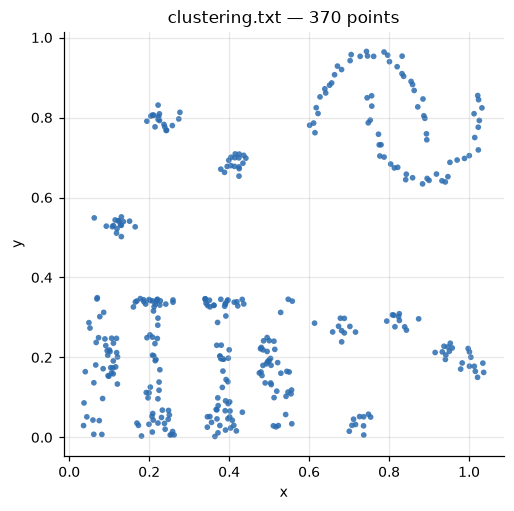

In [10]:
DATA_PATH = "clustering.txt"
X = np.loadtxt(DATA_PATH, delimiter=",", dtype=float)

assert X.ndim == 2 and X.shape[1] == 2, "expected one (x, y) pair per line"
N_POINTS = X.shape[0]

print(f"loaded {X.shape[0]} points with {X.shape[1]} features from {DATA_PATH}")
print(f"x range: [{X[:, 0].min():.3f}, {X[:, 0].max():.3f}]")
print(f"y range: [{X[:, 1].min():.3f}, {X[:, 1].max():.3f}]")
print(f"mean   : ({X[:, 0].mean():.3f}, {X[:, 1].mean():.3f})")
print(f"std    : ({X[:, 0].std():.3f}, {X[:, 1].std():.3f})")

fig, ax = plt.subplots(figsize=(6.2, 5.0))
ax.scatter(X[:, 0], X[:, 1], s=14, c="#2b6cb0", alpha=0.85, edgecolors="none")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"clustering.txt — {N_POINTS} points")
ax.set_aspect("equal", adjustable="box")
fig.savefig(os.path.join(FIG_DIR, "fig1_dataset.png"))
plt.show()

### Question 9 — how many natural clusters are there?

**Thirteen.** The dataset is not a handful of round blobs; it is a small "gallery" of 13
distinct point groups of three different shapes, all separated by clear empty space:

**Lower half ($y < 0.36$) — 8 groups:**

| # | shape | extent |
|---|---|---|
| 1 | vertical strip | $x \in [0.04, 0.12]$, $y \in [0.01, 0.35]$ (40 pts) |
| 2 | vertical strip | $x \in [0.16, 0.26]$, $y \in [0.00, 0.35]$ (60 pts) |
| 3 | vertical strip | $x \in [0.34, 0.44]$, $y \in [0.00, 0.35]$ (60 pts) |
| 4 | vertical strip | $x \in [0.48, 0.56]$, $y \in [0.03, 0.35]$ (40 pts) |
| 5 | small blob | $(0.62\text{–}0.72,\ 0.24\text{–}0.30)$ (10 pts) |
| 6 | small blob | $(0.70\text{–}0.75,\ 0.01\text{–}0.06)$ (10 pts) |
| 7 | small blob | $(0.79\text{–}0.87,\ 0.27\text{–}0.31)$ (10 pts) |
| 8 | horizontal blob | $(0.92\text{–}1.04,\ 0.15\text{–}0.24)$ (20 pts) |

**Upper half ($y > 0.50$) — 5 groups:** three compact blobs at
$(0.06\text{–}0.17,\ 0.50\text{–}0.55)$, $(0.19\text{–}0.28,\ 0.77\text{–}0.83)$ and
$(0.38\text{–}0.44,\ 0.65\text{–}0.71)$, and **two ring-shaped groups** at
$(0.60\text{–}0.89,\ 0.74\text{–}0.97)$ and $(0.75\text{–}1.03,\ 0.63\text{–}0.86)$.

So the answer is 13, and the shapes matter: four clusters are **elongated strips** and two are
**non-convex rings**. A coarser reading is possible — two groups (upper/lower) or four strips
plus a "rest" — but the gaps between the 13 groups are all much larger than the spacing
inside them, which is why both linkages find 13 clusters at a natural cut height.

## 3.2 HAC with incremental distance updates

The algorithm keeps a **cluster-level** distance matrix $D$ that is updated in place:

1. Compute the $n \times n$ point-to-point distance matrix once — the only place where
   individual points are compared.
2. Repeatedly take the nearest pair of active clusters $(A, B)$, record the merge
   (children, distance, size) for the dendrogram, and mark $B$ inactive.
3. **Incremental update** — the distance from the merged cluster $A \cup B$ to any other
   cluster $C$ is obtained from the *old row* only:
   * `min_dist` (single linkage): $d(A \cup B, C) = \min\{d(A,C),\, d(B,C)\}$
   * `max_dist` (complete linkage): $d(A \cup B, C) = \max\{d(A,C),\, d(B,C)\}$

   Both are elementwise reductions of the two existing rows, so the new distances cost
   $O(n)$ instead of $O(|A|\cdot|B|)$; **no cluster distance is ever computed by scanning
   pairs of points** after the initial matrix.

Because $D$ is maintained for all clusters, the same code supports any `dist_fn` passed as a
parameter. Complexity: $O(n^3)$ for the naive nearest-pair search, $O(n^2)$ memory, and
$O(n^2)$ work for all incremental updates combined.

In [11]:
def _pairwise_distances(X):
    """Full Euclidean distance matrix between the points (computed once)."""
    diff = X[:, None, :] - X[None, :, :]
    return np.sqrt(np.einsum("ijk,ijk->ij", diff, diff))


# Cluster-distance functions: they take the two *existing* rows of the distance
# matrix and return the new row of the merged cluster. This is the whole point of
# the incremental scheme -- no point pairs are touched here.
DIST_FUNCS = {
    "min": np.minimum,     # single linkage
    "max": np.maximum,     # complete linkage
}


def hac(X, dist_fn="min", verbose=False):
    """Hierarchical agglomerative clustering with incremental updates.

    Parameters
    ----------
    X : (n, d) array of points
    dist_fn : "min" (single linkage) or "max" (complete linkage)

    Returns
    -------
    dict with
        Z : (n-1, 4) linkage matrix [left_label, right_label, distance, size]
            (the format the dendrogram is drawn from)
        distances : merge distances in merge order
    """
    if dist_fn not in DIST_FUNCS:
        raise ValueError(f"dist_fn must be one of {sorted(DIST_FUNCS)}")
    reduce_fn = DIST_FUNCS[dist_fn]

    n = len(X)
    D = _pairwise_distances(X)              # the one and only O(n^2) point comparison
    np.fill_diagonal(D, np.inf)             # a cluster is never its own neighbour

    active = np.ones(n, dtype=bool)         # which matrix slots hold live clusters
    label = list(range(n))                  # cluster label (leaf id or merge id)
    size = np.ones(n, dtype=int)            # number of original points in the cluster
    Z = np.zeros((n - 1, 4))
    next_label = n

    for step in range(n - 1):
        # ---- nearest pair of active clusters -----------------------------
        idx = np.flatnonzero(active)
        sub = D[np.ix_(idx, idx)]
        pos = int(np.argmin(sub))
        i, j = idx[pos // len(idx)], idx[pos % len(idx)]
        if i > j:                                       # merge the higher index into i
            i, j = j, i
        d = float(D[i, j])

        # ---- record the merge: everything the dendrogram needs ------------
        Z[step] = (label[i], label[j], d, size[i] + size[j])

        # ---- incremental update of the new cluster's distances ------------
        D[i, :] = reduce_fn(D[i, :], D[j, :])           # row of the merged cluster
        D[:, i] = D[i, :]
        D[i, i] = np.inf
        active[j] = False                               # slot j is retired
        size[i] += size[j]
        label[i] = next_label
        next_label += 1

        if verbose and (step + 1) % 100 == 0:
            print(f"  {step + 1:>3} merges done, distance = {d:.4f}")

    return {"Z": Z, "distances": Z[:, 2].copy(), "dist_fn": dist_fn, "n": n}


def cut_tree(Z, n_clusters):
    """Cluster membership for a target number of clusters.

    The first ``n - n_clusters`` rows of the linkage matrix are exactly the merges
    that are performed while the number of clusters drops from n to n_clusters, so
    applying only those merges (union-find) yields the memberships.
    """
    n = Z.shape[0] + 1
    # labels: 0..n-1 are the points, n..2n-3 are the merged clusters, so the
    # union-find array must cover both ranges.
    parent = list(range(n + Z.shape[0]))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for i in range(n - n_clusters):
        left, right = int(Z[i, 0]), int(Z[i, 1])
        node = n + i                      # the cluster created by merge i
        parent[find(left)] = find(node)
        parent[find(right)] = find(node)

    roots, labels = {}, np.empty(n, dtype=int)
    for i in range(n):
        labels[i] = roots.setdefault(find(i), len(roots))
    return labels


def cut_height(Z, n_clusters):
    """Distance threshold between the last kept and the first discarded merge."""
    n = Z.shape[0] + 1
    lo = Z[n - n_clusters - 1, 2]
    hi = Z[n - n_clusters, 2] if n - n_clusters < n - 1 else lo * 1.05
    return lo, hi

## 3.3 Correctness checks

Two independent checks, both in the next cell:

1. **Tiny brute-force version** — for a 40-point sample, a deliberately naive
   implementation recomputes every cluster distance from all pairs of points after every
   merge. Its merge distances must match the incremental version exactly.
2. **SciPy cross-check** — `scipy.cluster.hierarchy.linkage` with `single` and `complete`
   linkage on all 370 points must produce the same merge distances, and `fcluster` must
   produce the same partition for 13 clusters.

If the incremental update were wrong, these assertions would fail.

In [12]:
def brute_force_hac(X, dist_fn="min", max_merges=None):
    """Deliberately naive O(n^3 * cluster) reference: recomputes cluster distances
    from ALL pairs of points after every merge. Used only to validate `hac`."""
    n = len(X)
    agg = "min" if dist_fn == "min" else "max"
    P = _pairwise_distances(X)             # point-to-point distances
    clusters = {i: [i] for i in range(n)}
    distances, links = [], []
    while len(clusters) > 1 and (max_merges is None or len(distances) < max_merges):
        keys = sorted(clusters)
        best, best_pair = np.inf, None
        for a_idx in range(len(keys)):
            for b_idx in range(a_idx + 1, len(keys)):
                A, B = keys[a_idx], keys[b_idx]
                # exhaustive comparison over all pairs of points of the two clusters
                block = P[np.ix_(clusters[A], clusters[B])]
                d = float(block.min() if agg == "min" else block.max())
                if d < best:
                    best, best_pair = d, (A, B)
        A, B = best_pair
        distances.append(best)
        links.append((A, B, best, len(clusters[A]) + len(clusters[B])))
        clusters[A] = clusters[A] + clusters[B]
        del clusters[B]
    return distances, links


small = X[np.random.default_rng(0).choice(len(X), size=40, replace=False)]
for mode in ("min", "max"):
    mine = hac(small, mode)["Z"][:, 2]
    ref, _ = brute_force_hac(small, mode)
    assert np.allclose(mine, ref), f"incremental update disagrees with brute force ({mode})"
    print(f"{mode}_dist: incremental == brute force on 40 points "
          f"(max |diff| = {np.max(np.abs(mine - np.array(ref))):.2e})")

# --- SciPy cross-check on the full dataset --------------------------------
from scipy.cluster.hierarchy import linkage as scipy_linkage, fcluster

for mode, method in (("min", "single"), ("max", "complete")):
    Z_mine = hac(X, mode)["Z"]
    Z_ref = scipy_linkage(X, method=method, metric="euclidean")
    same_d = np.allclose(Z_mine[:, 2], Z_ref[:, 2], rtol=1e-9, atol=1e-12)

    # canonical partition comparison at 13 clusters
    def canonical(labels):
        groups = defaultdict(list)
        for point, lab in enumerate(labels):
            groups[lab].append(point)
        return sorted(tuple(sorted(g)) for g in groups.values())

    mine13 = canonical(cut_tree(Z_mine, 13))
    thr = 0.5 * sum(cut_height(Z_ref, 13))
    ref13 = canonical(fcluster(Z_ref, thr, criterion="distance") - 1)
    print(f"{mode}_dist: merge distances match SciPy {method} linkage: {same_d}; "
          f"13-cluster partition identical to SciPy: {mine13 == ref13}")
    assert same_d and mine13 == ref13

min_dist: incremental == brute force on 40 points (max |diff| = 0.00e+00)


max_dist: incremental == brute force on 40 points (max |diff| = 0.00e+00)


min_dist: merge distances match SciPy single linkage: True; 13-cluster partition identical to SciPy: True
max_dist: merge distances match SciPy complete linkage: True; 13-cluster partition identical to SciPy: True


## 3.4 Plotting helpers

The dendrogram is drawn directly from the recorded linkage matrix (no SciPy plotting), so
the merge record kept by `hac` is what you see: leaves in their natural order, the height of
each join is the cluster distance at which the merge happened, and the dashed line marks the
cut that separates 13 clusters.

In [13]:
def plot_dendrogram(Z, n_clusters=None, title="", ax=None, figsize=(10, 4.2)):
    """Draw a dendrogram from a linkage matrix [left, right, distance, size]."""
    n = Z.shape[0] + 1
    pos, order = {}, []

    def place(node):
        """Recursively assign x positions; leaves get consecutive integers."""
        if node < n:
            pos[node] = float(len(order))
            order.append(int(node))
        else:
            left, right = int(Z[node - n, 0]), int(Z[node - n, 1])
            place(left)
            place(right)
            pos[node] = 0.5 * (pos[left] + pos[right])

    place(2 * n - 2)                     # labels n .. 2n-2 are the merges, root last

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    for step in range(Z.shape[0]):
        left, right, height = int(Z[step, 0]), int(Z[step, 1]), Z[step, 2]
        h_left = 0.0 if left < n else Z[left - n, 2]
        h_right = 0.0 if right < n else Z[right - n, 2]
        ax.plot([pos[left], pos[left]], [h_left, height], color="#4a5568", lw=0.8)
        ax.plot([pos[right], pos[right]], [h_right, height], color="#4a5568", lw=0.8)
        ax.plot([pos[left], pos[right]], [height, height], color="#4a5568", lw=0.8)

    if n_clusters is not None:
        lo, hi = cut_height(Z, n_clusters)
        ax.axhline(0.5 * (lo + hi), color="#c53030", ls="--", lw=1.2,
                   label=f"cut for {n_clusters} clusters")
        ax.legend(loc="upper right", fontsize=8)

    ax.set_xlim(-1, n)
    ax.set_xticks([])
    ax.set_xlabel("data points (leaf order)")
    ax.set_ylabel("cluster distance at merge")
    ax.set_title(title)
    ax.grid(False)
    return ax


def plot_clusters(X, labels, title="", ax=None, figsize=(6.2, 5.0)):
    """Scatter plot with one colour per cluster."""
    labels = np.asarray(labels)
    n_clusters = len(np.unique(labels))
    cmap = plt.get_cmap("tab20")
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    for c in range(n_clusters):
        members = X[labels == c]
        ax.scatter(members[:, 0], members[:, 1], s=16, color=cmap(c % 20),
                   alpha=0.9, edgecolors="none", label=f"{c} (n={len(members)})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=6, ncol=2, loc="center left", bbox_to_anchor=(1.01, 0.5),
              frameon=False, title="cluster (size)", title_fontsize=7)
    return ax

## 3.5 HAC with `min_dist` (single linkage)

Single linkage measures the gap between the two *closest* points of two clusters, so a
cluster will happily absorb any point that is close to *any* of its members. The
consequence is the familiar **chaining** effect: clusters string themselves together through
intermediate points, and such clusters can be long and thin. On this dataset, where four of
the natural clusters really are long and thin, that is a feature rather than a bug — but it
is also the reason single linkage is fragile in the presence of noise bridges.

  100 merges done, distance = 0.0095
  200 merges done, distance = 0.0151
  300 merges done, distance = 0.0234


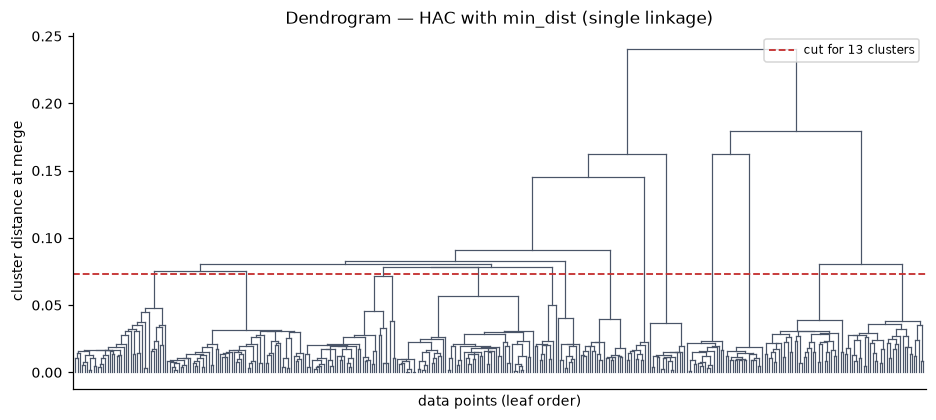

merge distances: smallest 0.0004, largest 0.2404
cut for 13 clusters lies between 0.0714 and 0.0753


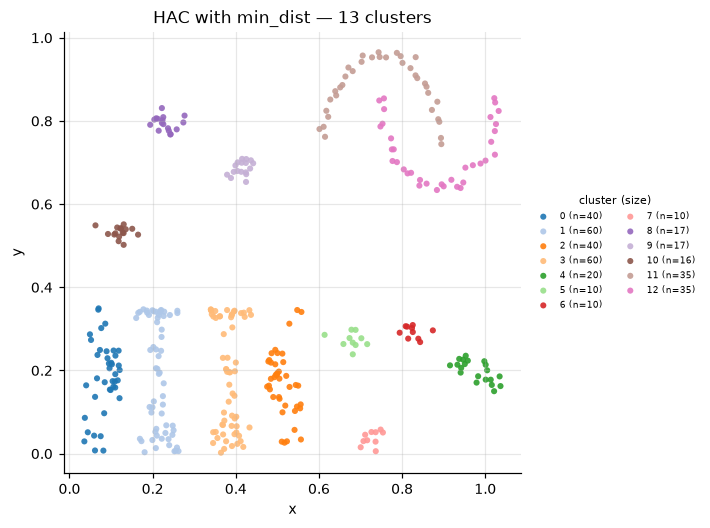

cluster sizes: {0: 40, 1: 60, 2: 40, 3: 60, 4: 20, 5: 10, 6: 10, 7: 10, 8: 17, 9: 17, 10: 16, 11: 35, 12: 35}
largest cluster 60 points, smallest 10 points, 0 singleton(s)


In [14]:
TARGET_CLUSTERS = 13
hac_min = hac(X, "min", verbose=True)
labels_min = cut_tree(hac_min["Z"], TARGET_CLUSTERS)

# --- dendrogram -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4.2))
plot_dendrogram(hac_min["Z"], TARGET_CLUSTERS,
                title="Dendrogram — HAC with min_dist (single linkage)", ax=ax)
fig.savefig(os.path.join(FIG_DIR, "fig2_dendrogram_min.png"))
plt.show()

print(f"merge distances: smallest {hac_min['distances'][0]:.4f}, "
      f"largest {hac_min['distances'][-1]:.4f}")
lo, hi = cut_height(hac_min["Z"], TARGET_CLUSTERS)
print(f"cut for {TARGET_CLUSTERS} clusters lies between {lo:.4f} and {hi:.4f}")

# --- colour-coded clusters ------------------------------------------------
fig, ax = plt.subplots(figsize=(7.2, 5.2))
plot_clusters(X, labels_min, title=f"HAC with min_dist — {TARGET_CLUSTERS} clusters", ax=ax)
fig.savefig(os.path.join(FIG_DIR, "fig3_clusters_min.png"))
plt.show()

sizes_min = np.bincount(labels_min)
print("cluster sizes:", dict(enumerate(sizes_min.tolist())))
print(f"largest cluster {sizes_min.max()} points, smallest {sizes_min.min()} points, "
      f"{int((sizes_min == 1).sum())} singleton(s)")

## 3.6 HAC with `max_dist` (complete linkage)

Complete linkage measures the distance between the two *farthest* points of two clusters, so
merging is only allowed when **every** pair of points across the two clusters is close.
Clusters therefore stay compact and roughly spherical — ideal for the three round blobs, but
impossible for a strip or a ring, whose two ends are far apart however dense the shape is.

  100 merges done, distance = 0.0111
  200 merges done, distance = 0.0225


  300 merges done, distance = 0.0593


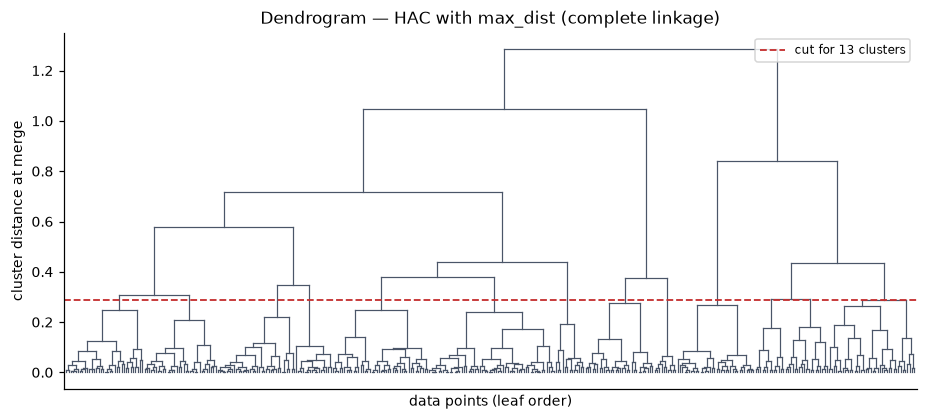

merge distances: smallest 0.0004, largest 1.2858
cut for 13 clusters lies between 0.2877 and 0.2902


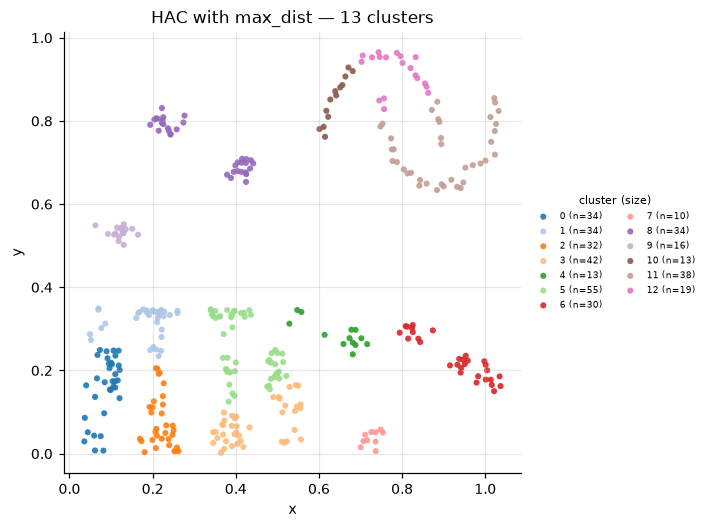

cluster sizes: {0: 34, 1: 34, 2: 32, 3: 42, 4: 13, 5: 55, 6: 30, 7: 10, 8: 34, 9: 16, 10: 13, 11: 38, 12: 19}
largest cluster 55 points, smallest 10 points, 0 singleton(s)


In [15]:
hac_max = hac(X, "max", verbose=True)
labels_max = cut_tree(hac_max["Z"], TARGET_CLUSTERS)

fig, ax = plt.subplots(figsize=(10, 4.2))
plot_dendrogram(hac_max["Z"], TARGET_CLUSTERS,
                title="Dendrogram — HAC with max_dist (complete linkage)", ax=ax)
fig.savefig(os.path.join(FIG_DIR, "fig4_dendrogram_max.png"))
plt.show()

print(f"merge distances: smallest {hac_max['distances'][0]:.4f}, "
      f"largest {hac_max['distances'][-1]:.4f}")
lo, hi = cut_height(hac_max["Z"], TARGET_CLUSTERS)
print(f"cut for {TARGET_CLUSTERS} clusters lies between {lo:.4f} and {hi:.4f}")

fig, ax = plt.subplots(figsize=(7.2, 5.2))
plot_clusters(X, labels_max, title=f"HAC with max_dist — {TARGET_CLUSTERS} clusters", ax=ax)
fig.savefig(os.path.join(FIG_DIR, "fig5_clusters_max.png"))
plt.show()

sizes_max = np.bincount(labels_max)
print("cluster sizes:", dict(enumerate(sizes_max.tolist())))
print(f"largest cluster {sizes_max.max()} points, smallest {sizes_max.min()} points, "
      f"{int((sizes_max == 1).sum())} singleton(s)")

### Question 10 — do the `min_dist` clusters match intuition?

**Yes — almost exactly.** Each of the 13 groups of Question 9 comes out as exactly one
cluster, including the four elongated strips (they keep their full height, $y = 0 \to 0.35$,
and their narrow width, $0.09$) and the two rings (each ring is one colour, although its
diameter is 0.30 while its points are only ~0.02 apart along the ring). Cluster sizes are
60, 60, 40, 40, 35, 35, 20, 17, 17, 16, 10, 10, 10 and there are **no singletons** — every
cluster has at least the 10 points the data actually gives it.

The one thing to criticise is that the strips are *long* clusters, and a long chain of points
that happened to connect two groups would be merged by single linkage without hesitation:
the cut height (0.071 – 0.075) is much smaller than the strips' diameter (0.35), so single
linkage is following connectivity, not compactness. In this dataset that is exactly right,
because the strips really are contiguous; on noisy data with a bridge of points between two
groups it would be wrong.

### Question 11 — do the `max_dist` clusters match intuition?

**No — noticeably worse.** The 13 clusters of complete linkage no longer follow the shapes:

* **The four vertical strips are cut horizontally into halves**: e.g. strip 2 becomes
  $x \in [0.17, 0.26], y \in [0.00, 0.21]$ (32 pts) and $x \in [0.17, 0.26], y \in [0.21, 0.35]$
  (34 pts). The cut has nothing to do with the data — it appears because a strip's diameter
  (0.35) exceeds the height at which complete linkage is willing to merge.
* **The halves of *different* strips are then merged**: cluster 1 spans $x \in [0.05, 0.26]$ at
  $y \in [0.24, 0.35]$ (the tops of strips 1 and 2, 34 pts), and cluster 3 spans
  $x \in [0.35, 0.56]$ at $y \in [0.00, 0.17]$ (the bottoms of strips 3 and 4, 42 pts). Two
  visually separate groups end up in one cluster, while one group sits in two clusters.
* **The big ring is broken into two arcs**: a left arc $x \in [0.60, 0.68], y \in [0.76, 0.93]$
  (13 pts) and a top arc $x \in [0.70, 0.86], y \in [0.83, 0.97]$ (19 pts). The right ring
  survives whole (38 pts), but only because it is smaller.
* Two of the upper blobs are merged into a single 34-point cluster
  ($x \in [0.19, 0.44], y \in [0.65, 0.83]$), again because their diameter is small enough.

So complete linkage produces 13 *compact* clusters, but not the 13 clusters that are in the
data: it splits every elongated shape and glues the pieces across groups.

### Question 12 — which clustering agrees more with intuition, and why?

**`min_dist` (single linkage) agrees much more with intuition on this dataset**, because the
natural clusters are **elongated or non-convex** and single linkage is the only one of the
two that can represent them.

The reason is visible in the two definitions:

* `min_dist` merges two clusters as soon as **one** pair of points is close,
  $d(A,B) = \min_{a \in A, b \in B} \|a-b\|$. Along a strip or around a ring, consecutive
  points are ~0.01 apart even though the shape is 0.35 wide, so the cluster can grow along
  the shape without ever asking how far its two ends are. The price is **chaining**: any
  sparse path of points between two groups would merge them.
* `max_dist` merges only when **every** pair is close,
  $d(A,B) = \max_{a \in A, b \in B} \|a-b\|$. That keeps clusters compact and roughly
  spherical — excellent for the three round blobs, which it recovers well — but it caps a
  cluster's diameter at the merge height. Since the strips and rings have diameter ≈ 0.35
  and the merge height is ≈ 0.29, complete linkage *must* cut them, and it cuts them
  wherever the diameter constraint bites: mid-strip, and across the ring.

In short: `min_dist` answers "which points are connected?", `max_dist` answers "which points
fit in a ball?". This dataset contains strips and rings, so the connectivity answer is the
one that matches the eye.

## 4. Saving the results for the report

All numbers and figure paths used in `HW4_Report.pdf` are written to
`results/hw4_results.json`, so the report can be rebuilt without re-running the analysis.

In [16]:
def cluster_summary(X, labels):
    """Sizes and centroids of the clusters in ``labels``."""
    out = []
    for c in range(len(np.unique(labels))):
        members = X[labels == c]
        out.append({"cluster": int(c), "size": int(len(members)),
                    "centroid": [round(float(v), 4) for v in members.mean(axis=0)]})
    return out


results = {
    "meta": {
        "seed": SEED,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "n_transactions": N_TRANS,
        "n_items": len(item_counts),
        "min_sup": MIN_SUP,
        "min_conf": MIN_CONF,
        "n_points": int(N_POINTS),
        "target_clusters": TARGET_CLUSTERS,
    },
    "item_support": {item: c / N_TRANS for item, c in sorted(item_counts.items())},
    "apriori": {
        "levels": {k: {"candidates": apriori_log[k]["candidates"],
                       "pruned": len(apriori_log[k]["pruned"]),
                       "kept": apriori_log[k].get("kept", len(levels.get(k, {}))),
                       "frequent": len(levels.get(k, {})),
                       "itemsets": [{"itemset": sorted(fs), "support": s}
                                    for fs, s in sorted(levels.get(k, {}).items(),
                                                        key=lambda kv: (-kv[1], sorted(kv[0])))],
                       "pruned_detail": [{"candidate": sorted(c), "missing_subset": sorted(m)}
                                         for c, m in apriori_log[k]["pruned"].items()]}
                   for k in sorted(apriori_log)},
        "total_frequent": len(frequent),
    },
    "q4": {
        "singletons": {item: support({item}, TRANS_SETS) for item in target},
        "pairs": {" & ".join(p): support(p, TRANS_SETS)
                  for p in map(tuple, combinations(target, 2))},
        "triple_support": support(target, TRANS_SETS),
        "is_candidate": target_fs in cand3,
        "is_pruned": target_fs in pruned3,
        "pruned_reason": sorted(pruned3[target_fs]) if target_fs in pruned3 else None,
        "n_candidates_k3": len(cand3),
    },
    "rules": [{**r, "antecedent": list(r["antecedent"]),
               "consequent": list(r["consequent"]), "itemset": list(r["itemset"])}
              for r in rules],
    "rules_pruning": [{"itemset": list(rec["itemset"]), "k": rec["k"],
                       "candidates": rec["candidates"], "pruned": rec["pruned"],
                       "pruned_detail": [{"consequent": sorted(c), "missing_subset": sorted(m)}
                                         for c, m in rec["pruned_detail"].items()]}
                      for rec in rules_log],
    "clustering": {
        "min": {"sizes": sizes_min.tolist(), "clusters": cluster_summary(X, labels_min),
                "max_merge_distance": float(hac_min["distances"][-1]),
                "cut_range": [float(v) for v in cut_height(hac_min["Z"], TARGET_CLUSTERS)],
                "labels": labels_min.tolist()},
        "max": {"sizes": sizes_max.tolist(), "clusters": cluster_summary(X, labels_max),
                "max_merge_distance": float(hac_max["distances"][-1]),
                "cut_range": [float(v) for v in cut_height(hac_max["Z"], TARGET_CLUSTERS)],
                "labels": labels_max.tolist()},
    },
    "figures": {name: os.path.join("figures", name) for name in [
        "fig1_dataset.png", "fig2_dendrogram_min.png", "fig3_clusters_min.png",
        "fig4_dendrogram_max.png", "fig5_clusters_max.png"]},
}

out_path = os.path.join(RESULT_DIR, "hw4_results.json")
with open(out_path, "w", encoding="utf-8") as fh:
    json.dump(results, fh, indent=2, default=float)
print("wrote", out_path)
print("frequent itemsets:", len(frequent), "| rules:", len(rules),
      "| clusters:", TARGET_CLUSTERS, "(both distance functions)")

wrote C:\Users\hammerhao\Documents\GitHub\CS6220HW4\results\hw4_results.json
frequent itemsets: 10 | rules: 11 | clusters: 13 (both distance functions)


<a id="Summary-of-findings"></a>
## Summary of findings

* **Apriori** finds 10 frequent itemsets at `min_sup = 0.25` (5 singletons, 4 pairs and one
  triple). Pruning never fires at $k \le 2$ (nothing can be pruned there) but removes
  **2 of the 3** length-3 candidates before any support count, and the loop terminates at
  $k = 4$ with no candidate left.
* The itemset {Butter, Bread, Eggs} **is** proposed as a length-3 candidate by the join step
  and **is** pruned, because its 2-subset {Butter, Eggs} has support 0.15 < 0.25; its own
  support is also only 0.15 — downward closure and the data agree.
* **Apriori_rules** returns 11 rules at `min_conf = 0.6`. The strongest is
  `{Bread, Milk} -> {Butter}` (support 0.25, confidence 1.00, lift 3.33); the weakest is
  `{Bread} -> {Milk}` (confidence 0.625, lift 1.14) because Milk alone already appears in
  55 % of the baskets.
* **HAC** on `clustering.txt` confirms **13** natural clusters: four elongated vertical
  strips, four small lower-right blobs, three upper blobs and two ring-shaped groups. With
  13 clusters, `min_dist` recovers all 13 shapes exactly (no singletons), while `max_dist`
  cuts the strips and the rings into pieces and even merges the halves of different strips.
  Single linkage wins here because its connectivity criterion can follow an elongated shape;
  complete linkage's diameter criterion cannot.